## Policy Evaluation: TD(0), TD(λ), True Online TD(λ)

We compare three online evaluators using two feature matrices (tabular and shared linear features) on each environment. The policy is fixed during evaluation; all methods minimize costs.

The underlying stochastic TD formula follows the lecture and Q2:

\(\widetilde F_t(\theta_t)=\phi_t\left(\phi_t^\top\theta_t-c_t-\gamma\phi_{t+1}^\top\theta_t\right),\qquad \theta_{t+1}=\theta_t-\eta\widetilde F_t(\theta_t).\)

With $\delta_t=c_t+\gamma\phi_{t+1}^\top\theta_t-\phi_t^\top\theta_t$, the update is $\theta_{t+1}=\theta_t+\eta\delta_t\phi_t$.

Run the notebook using Kernel → Restart & Run All after installing the package (`pip install -e ".[notebooks]"`). The methods live in `ie692_rl.enhancements.true_online_td`; features are one-hot index tables, so `features.n_features` is the parameter count.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from ie692_rl.core import ExactScorer
from ie692_rl.enhancements.true_online_td import (
    linear_features,
    tabular_features,
    td_lambda,
    td_zero,
    true_online_td_lambda,
)
from ie692_rl.envs import Blackjack, GridWorld

plt.style.use("ggplot")

REPO = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
ENVIRONMENTS = ["blackjack", "gridworld"]
N_STEPS = 2000  # Online training transitions per method
RECORD_EVERY = 100
ETA = 0.05
LAM = 0.8
SEED = 42
REFERENCE_ROLLOUTS = 300  # Independent validation only; not training
REFERENCE_HORIZON = 80
RUN_TOMC = False  # Optional; GridWorld needs ~0.2M-1.4M steps per estimate

output = REPO / "results" / "td_evaluation"
output.mkdir(parents=True, exist_ok=True)

In [2]:
def validate_start_value(env, pi, s_0, rng):
    returns = []
    for _ in range(REFERENCE_ROLLOUTS):
        s = s_0
        total = 0.0
        discount = 1.0
        for _ in range(REFERENCE_HORIZON):
            a = int(rng.choice(env.n_actions, p=pi[s]))
            next_s, cost, done = env.step_one(s, a, rng)
            total += discount * cost
            if done:
                break
            discount *= env.gamma
            s = next_s
        returns.append(total)
    return float(np.mean(returns))

## Run the six TD configurations
For conventional TD(λ), we use $e_t=\gamma\lambda e_{t-1}+\phi_t$ and $\theta_{t+1}=\theta_t+\eta\delta_te_t$.

True Online TD(λ) uses the Dutch trace

\(e_t=\gamma\lambda e_{t-1}+(1-\eta\gamma\lambda e_{t-1}^\top\phi_t)\phi_t\)

and the correction term shown in the proposal. The traces reset at Blackjack termination; GridWorld is continuing. All methods use the same random seed and observation budget for easy comparison.

In [3]:
all_results = {}

for name in ENVIRONMENTS:
    env = Blackjack() if name == "blackjack" else GridWorld()
    s_0 = env.start  # Blackjack: (total 8, dealer shows 3); GridWorld: the origin
    pi = np.full((env.n_states, env.n_actions), 1 / env.n_actions)
    reference_v = validate_start_value(env, pi, s_0, np.random.default_rng(SEED + 100))
    exact_v = float(ExactScorer(env).values(pi)[s_0])

    records = []
    for feature_name, feature_fn in [("Tabular", tabular_features), ("Linear", linear_features)]:
        features = feature_fn(env)
        for method_name, td_fn in [
            ("TD(0)", td_zero),
            ("TD(lambda)", td_lambda),
            ("True Online TD(lambda)", true_online_td_lambda),
        ]:
            kwargs = {
                "env": env,
                "pi": pi,
                "features": features,
                "n_steps": N_STEPS,
                "eta": ETA,
                "rng": np.random.default_rng(SEED),
                "record_every": RECORD_EVERY,
            }
            if td_fn is not td_zero:
                kwargs["lam"] = LAM
            result = td_fn(**kwargs)
            for observations, estimated_v in zip(result.history_steps, result.history_values, strict=True):
                records.append(
                    {
                        "method": method_name,
                        "features": feature_name,
                        "observations": int(observations),
                        "estimated_v": float(estimated_v),
                        "absolute_value_difference": abs(float(estimated_v) - reference_v),
                    }
                )
            print(
                f"{name:10} | {feature_name:7} | {method_name:23} | "
                f"parameters={features.n_features:3} | observations={result.observations}"
            )

    results = pd.DataFrame(records)
    all_results[name] = {"results": results, "reference_v": reference_v}
    results.to_csv(output / f"{name}_td_history.csv", index=False)
    print(f"{name} sampled reference V(s_0): {reference_v:.4f} (exact: {exact_v:.4f})\n")

blackjack  | Tabular | TD(0)                   | parameters= 64 | observations=2000
blackjack  | Tabular | TD(lambda)              | parameters= 64 | observations=2000
blackjack  | Tabular | True Online TD(lambda)  | parameters= 64 | observations=2000
blackjack  | Linear  | TD(0)                   | parameters= 16 | observations=2000
blackjack  | Linear  | TD(lambda)              | parameters= 16 | observations=2000
blackjack  | Linear  | True Online TD(lambda)  | parameters= 16 | observations=2000
blackjack sampled reference V(s_0): 0.6057 (exact: 0.5406)



gridworld  | Tabular | TD(0)                   | parameters=400 | observations=2000
gridworld  | Tabular | TD(lambda)              | parameters=400 | observations=2000
gridworld  | Tabular | True Online TD(lambda)  | parameters=400 | observations=2000
gridworld  | Linear  | TD(0)                   | parameters=100 | observations=2000
gridworld  | Linear  | TD(lambda)              | parameters=100 | observations=2000
gridworld  | Linear  | True Online TD(lambda)  | parameters=100 | observations=2000
gridworld sampled reference V(s_0): 2.2702 (exact: 2.2870)



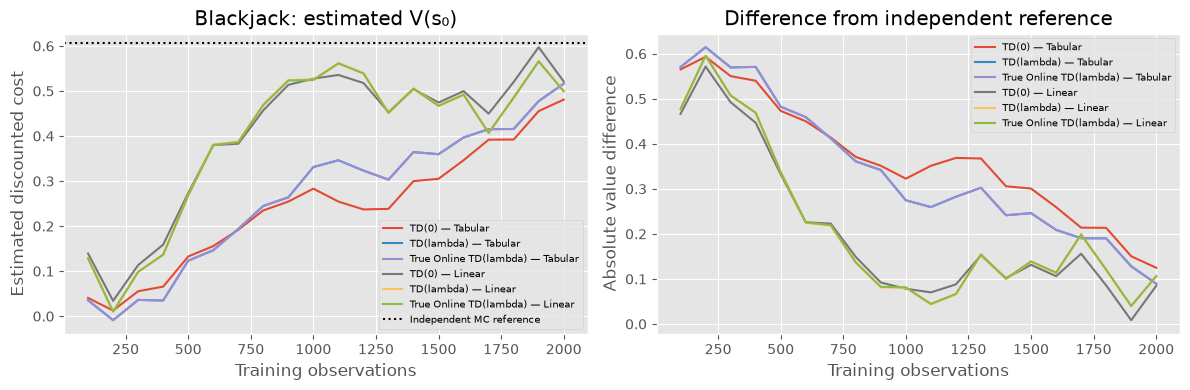

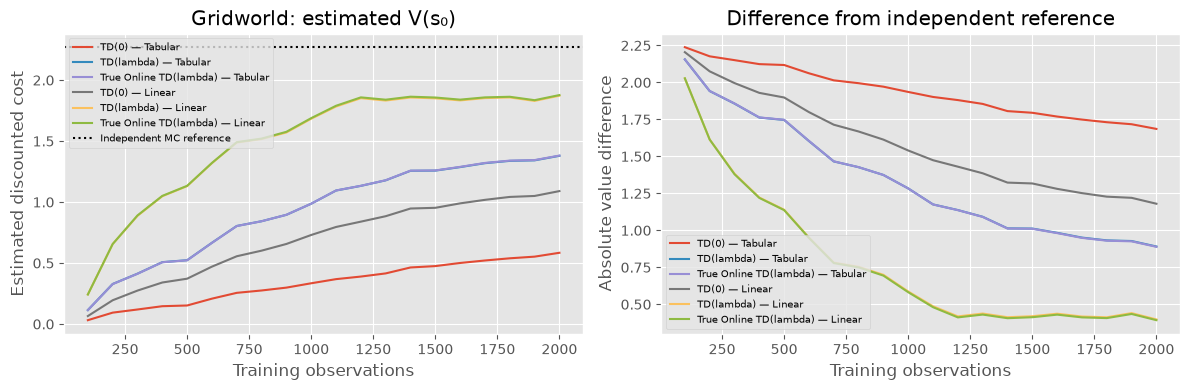

In [4]:
for name, result in all_results.items():
    data = result["results"]
    reference_v = result["reference_v"]

    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    for (features, method), group in data.groupby(["features", "method"], sort=False):
        label = f"{method} — {features}"
        axes[0].plot(group.observations, group.estimated_v, label=label)
        axes[1].plot(group.observations, group.absolute_value_difference, label=label)

    axes[0].axhline(reference_v, color="black", linestyle="dotted", label="Independent MC reference")
    axes[0].set(
        xlabel="Training observations",
        ylabel="Estimated discounted cost",
        title=f"{name.title()}: estimated V(s₀)",
    )
    axes[1].set(
        xlabel="Training observations",
        ylabel="Absolute value difference",
        title="Difference from independent reference",
    )
    axes[0].legend(fontsize=7)
    axes[1].legend(fontsize=7)
    fig.tight_layout()
    fig.savefig(output / f"{name}_td_comparison.png", dpi=160)
    plt.show()

In [5]:
if RUN_TOMC:
    from ie692_rl.core import TOMC

    for name in ENVIRONMENTS:
        env = Blackjack() if name == "blackjack" else GridWorld()
        pi = np.full((env.n_states, env.n_actions), 1 / env.n_actions)
        try:
            Q, n, _ = TOMC(bias=0.01).estimate(env, pi, np.random.default_rng(SEED), 2_000_000)
            print(name, "TOMC observations:", n, "estimated V(s0):", float(pi[env.start] @ Q[env.start]))
        except RuntimeError as error:
            print(name, error)